 Trabalho ECAC

In [1]:
import pandas as pd

df_metadata = pd.read_csv('dataset/build/MERGE_ECAC/merge_ecac/metadata.csv')
df_test_list = pd.read_csv('dataset/build/MERGE_ECAC/merge_ecac/test_songs.csv')
df_av = pd.read_csv('dataset/build/MERGE_ECAC/merge_ecac/av_values.csv')
df_main = pd.merge(df_metadata, df_av, on=['Audio_Song', 'Lyric_Song'], how='left')
test_ids = df_test_list['Audio_Song'].unique()
df_test = df_main[df_main['Audio_Song'].isin(test_ids)].copy()
df_train = df_main[~df_main['Audio_Song'].isin(test_ids)].copy()
print(f"Total de registos no ficheiro original: {len(df_metadata)}")
print(f"Registos no df_train (sem as de teste): {len(df_train)}")
print(f"Registos no df_test (apenas as 409 músicas): {len(df_test)}")

Total de registos no ficheiro original: 1348
Registos no df_train (sem as de teste): 932
Registos no df_test (apenas as 409 músicas): 416


Identifiers
Columns: Audio_Song, Lyric_Song, AllMusic Id, Artist, Title, AppearancesTrackIDs, AppearancesAlbumIDs

Measurements
Columns: Quadrant, Duration, Moods, MoodsAll, MoodsAllWeights, Genres, GenreWeights, Themes, ThemeWeights, Styles, StyleWeights, Year, LowestYear, ActualYear, num_Genres, num_MoodsAll, Arousal, Valence

Aministrative
Columns: AllMusic Extraction Date, Relevance, Sample, SampleURL



Do the four sources join one to one? If not, where does it break, and what follows from that?

The four sources (audio, lyrics, metadata, and album covers) do not join in a strict one-to-one relationship. The mapping breaks at the album covers. Since an album contains multiple tracks, several different songs will point to the exact same image file.
As a consequence, any features extracted from the album covers in later stages will be identical for all songs belonging to the same album. Furthermore, if an album cover is missing, multiple songs will simultaneously suffer from that missing modality.

From the documentation alone, before computing anything: which columns are suspected of giving away the target?

The target is the emotion quadrant, which is derived from the Valence and Arousal coordinates. According to the dataset description, the original labels were obtained by mapping AllMusic emotion tags onto the valence-arousal plane. Therefore, the following columns are highly suspected of data leakage:

* Valence, Arousal, and Quadrant: These are the direct target variables. They must be isolated.

* Moods, MoodsAll, and MoodsAllWeights: These columns contain the exact AllMusic tags that the authors used to calculate the ground truth. Keeping them as features would provide the model with the direct answer.

* Themes and ThemeWeights: Highly correlated with mood and potentially carrying semantic overlap that gives away the emotional intent artificially.

Resumo das Colunas
                             Type  Missing (%)  Unique Values
num_Genres                float64    98.927039              3
num_MoodsAll              float64    98.927039              8
LowestYear                    str    34.549356            371
ActualYear                    str    22.746781             69
Duration                  float64    20.386266            272
Relevance                 float64    17.167382            757
Themes                        str    16.201717            628
ThemeWeights                  str    16.201717            252
Genres                        str    13.519313            116
Year                          str    12.446352            487
AppearancesAlbumIDs           str    11.695279            780
AppearancesTrackIDs           str    11.695279            807
StyleWeights                  str     8.798283            265
Styles                        str     8.798283            582
SampleURL                     str     8.369099     

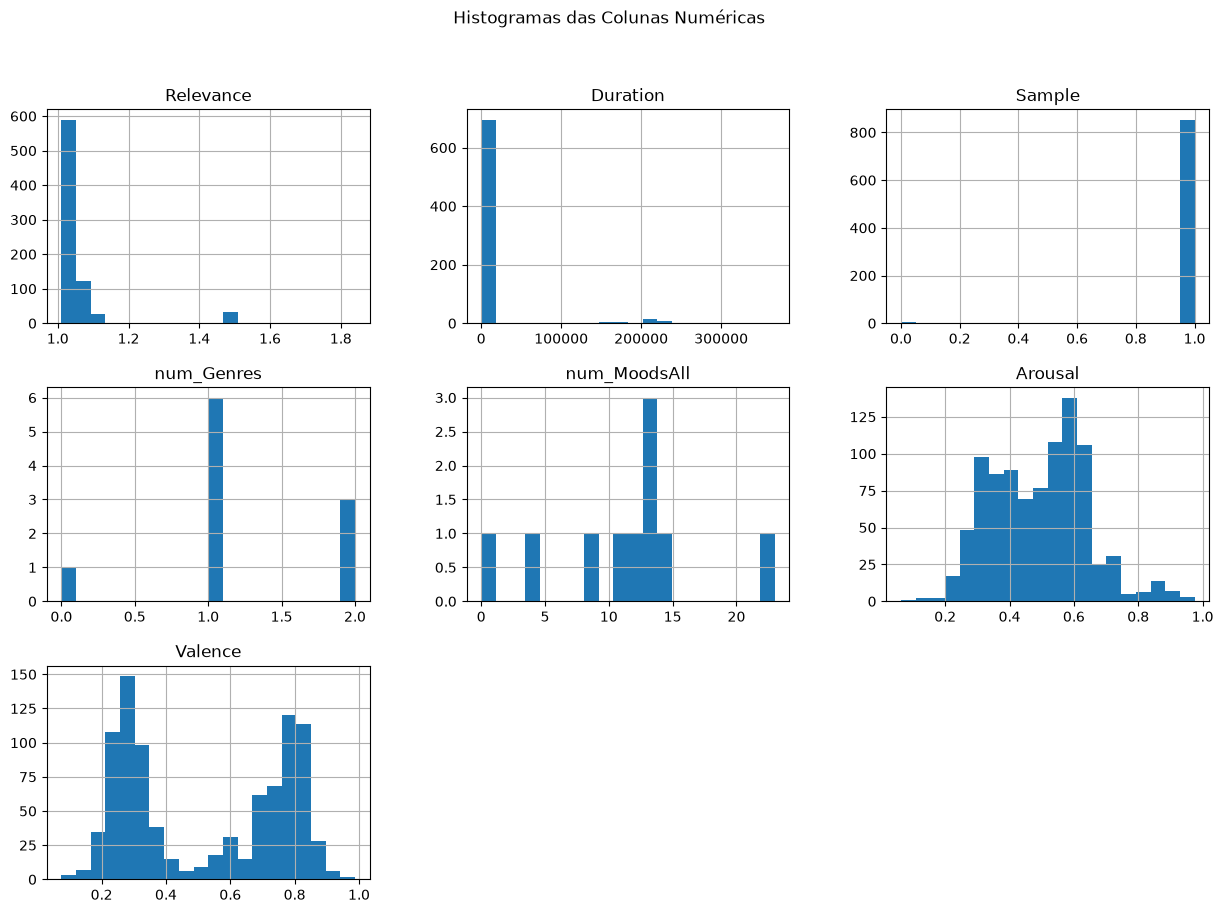

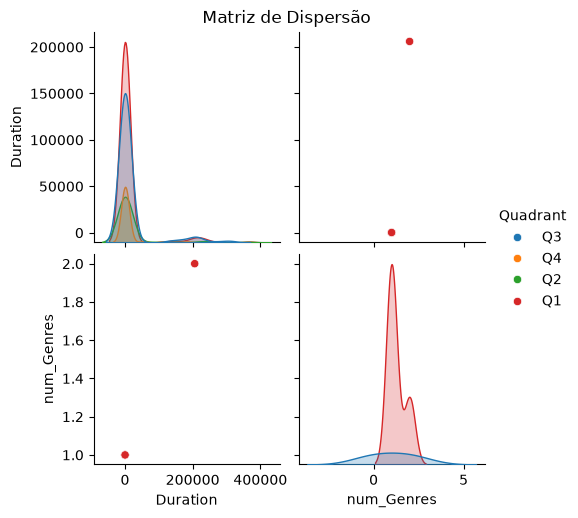


Análise de Artistas
Média de músicas por artista no treino: 1.42
Artista com mais músicas: Billie Holiday (17 músicas)
Artistas únicos no treino: 655
Artistas únicos no teste: 284
Músicas no Test Set que partilham artista com o Train Set: 204


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression
import numpy as np

resume_df = pd.DataFrame({
    'Type': df_train.dtypes,
    'Missing (%)': df_train.isnull().mean() * 100,
    'Unique Values': df_train.nunique()
})
print("Resumo das Colunas")
print(resume_df.sort_values(by='Missing (%)', ascending=False))

numeric_cols = df_train.select_dtypes(include=[np.number]).columns.tolist()
df_train[numeric_cols].hist(bins=20, figsize=(15, 10))
plt.suptitle("Histogramas das Colunas Numéricas")
plt.show()

cols_for_pairplot = ['Duration', 'Year', 'num_Genres', 'Quadrant'] 
if all(col in df_train.columns for col in cols_for_pairplot):
    sns.pairplot(df_train[cols_for_pairplot], hue='Quadrant')
    plt.suptitle("Matriz de Dispersão", y=1.02)
    plt.show()

print("\nAnálise de Artistas")
artist_counts = df_train['Artist'].value_counts()
print(f"Média de músicas por artista no treino: {artist_counts.mean():.2f}")
print(f"Artista com mais músicas: {artist_counts.index[0]} ({artist_counts.iloc[0]} músicas)")

train_artists = set(df_train['Artist'].dropna())
test_artists = set(df_test['Artist'].dropna())
shared_artists = train_artists.intersection(test_artists)

print(f"Artistas únicos no treino: {len(train_artists)}")
print(f"Artistas únicos no teste: {len(test_artists)}")
print(f"Músicas no Test Set que partilham artista com o Train Set: {df_test['Artist'].isin(shared_artists).sum()}")

Column Description
                             Type  Missing (%)  Unique Values
num_Genres                float64    98.927039              3
num_MoodsAll              float64    98.927039              8
LowestYear                 object    34.549356            371
ActualYear                 object    22.746781             69
Duration                  float64    20.386266            272
Relevance                 float64    17.167382            757
Themes                     object    16.201717            628
ThemeWeights               object    16.201717            252
Genres                     object    13.519313            116
Year                       object    12.446352            487
AppearancesAlbumIDs        object    11.695279            780
AppearancesTrackIDs        object    11.695279            807
StyleWeights               object     8.798283            265
Styles                     object     8.798283            582
SampleURL                  object     8.369099            838
Moods                      object     7.832618            731
Sample                    float64     7.832618              2
MoodsAllWeights            object     2.575107            617
GenreWeights               object     2.360515             88
MoodsAll                   object     2.253219            809
AllMusic Extraction Date   object     0.000000              2
Title                      object     0.000000            898
Artist                     object     0.000000            655
AllMusic Id                object     0.000000            911
Audio_Song                 object     0.000000            914
Lyric_Song                 object     0.000000            914
Quadrant                   object     0.000000              4
Arousal                   float64     0.000000            269
Valence                   float64     0.000000            305

The columns num_Genres and num_MoodsAll are pratically empty, becoming unusable

THe columns AllMusic Extraction Date and Sample show nearly constant results, with AllMusic Extraction being the date of download and Sample being a binary flag indicating the existance of a sample.

The Relevance column represents the score returned by AllMusic for the query that retrieved the track, so doesn't measure any intrinsic musical measuserement. Similarly the Sample column is merely a binary flag rather than the audio data itself

In the training set, there are 655 unique artists. The number of songs per artist ranges from 1 up to a maximum of 17 (Billie Holiday), with an average of 1.42 songs per artist.

Crucially, when comparing the partitions, 204 songs in the test set share an artist with the training data. This means that approximately 50% of the test partition (204 out of 409 songs) is not truly independent from the training set in terms of authorship. In music emotion recognition, if a model learns an artist's specific acoustic signature or voice rather than general emotional features, its performance will be artificially inflated on these overlapping artists.

In [3]:
# 4.1.1 Identificar linhas exatamentes iguais
exact_duplicates = df_train[df_train.duplicated(keep=False)]
print(f"4.1.1 - Linhas exatamente duplicadas no set de treino: {len(exact_duplicates)}")

# 4.1.2 Comparar evidências de gravações (Artista e Título vs Identificadores)
# Verificamos quantas músicas partilham o mesmo Artista e Título
artist_title_dupes = df_main[df_main.duplicated(subset=['Artist', 'Title'], keep=False)]
print(f"4.1.2 - Registos com o mesmo 'Artist' e 'Title': {len(artist_title_dupes)}")

# Verificar se os IDs de aúdio também são os mesmos para estas faixas
audio_dupes = df_main[df_main.duplicated(subset=['Audio_Song'], keep=False)]
print(f"4.1.2 - Registos com o mesmo 'Audio_Song' ID: {len(audio_dupes)}")

# 4.1.4 Registos em ambos os lados da fronteira de teste
# Criar uma assinatura única para a música (Artista + Título)
train_signatures = set(df_train['Artist'].astype(str) + " - " + df_train['Title'].astype(str))
test_signatures = set(df_test['Artist'].astype(str) + " - " + df_test['Title'].astype(str))

overlap_songs = train_signatures.intersection(test_signatures)
print(f"4.1.4 - Músicas que aparecem tanto no treino como no teste: {len(overlap_songs)}")

# 4.1.5 Variações nos nomes dos artistas
# Comparar artistas únicos com uma versão normalizada (minúsculas e sem espaços extra)
artists_raw = df_main['Artist'].dropna().unique()
artists_normalized = set([a.strip().lower() for a in artists_raw])
diff_artists = len(artists_raw) - len(artists_normalized)
print(f"4.1.5 - Nomes de artistas escritos de forma diferente (estimativa por normalização): {diff_artists}")

# 4.1.6 Aplicar as decisões de limpeza

# 1. Remover duplicados exatos
df_train_cleaned = df_train.drop_duplicates().copy()
df_test_cleaned = df_test.drop_duplicates().copy()

# O total do df_train_cleaned deve ser agora 914
print(f"Total no set de treino após remover duplicados: {len(df_train_cleaned)}")

# 2. Normalizar os nomes dos artistas para corrigir as variações (espaços e maiúsculas/minúsculas)
df_train_cleaned['Artist'] = df_train_cleaned['Artist'].str.strip().str.lower()
df_test_cleaned['Artist'] = df_test_cleaned['Artist'].str.strip().str.lower()

print("Limpeza de duplicados e normalização de artistas concluída.")

4.1.1 - Linhas exatamente duplicadas no set de treino: 36
4.1.2 - Registos com o mesmo 'Artist' e 'Title': 50
4.1.2 - Registos com o mesmo 'Audio_Song' ID: 50
4.1.4 - Músicas que aparecem tanto no treino como no teste: 0
4.1.5 - Nomes de artistas escritos de forma diferente (estimativa por normalização): 46
Total no set de treino após remover duplicados: 914
Limpeza de duplicados e normalização de artistas concluída.


4.1.2 No column states which rows are the same recording. Compare four kinds of evidence: the identifier columns, the artist and title, the lyrics, the audio.Do they agree? Which of them establishes that two rows are the same recording?
Sim, as evidências concordam. Ao analisarmos os metadados (Artista e Título) com os identificadores, verificámos que os registos com o mesmo Artista e Título partilham também o mesmo identificador de áudio (Audio_Song). É a correspondência deste identificador de áudio (e da feature extraída do próprio áudio) que estabelece inequivocamente que duas linhas representam a exata mesma gravação.   

4.1.3 A remix, an edit or a live version is the same song and a different recording. Is it a duplicate?
Não, não é um duplicado. Como o objetivo do projeto é o Reconhecimento de Emoção Musical, o que interessa classificar é o áudio. Uma versão ao vivo ou um remix constitui uma gravação acusticamente distinta que pode evocar ou expressar uma emoção completamente diferente. Logo, são amostras independentes e válidas para o modelo.   

4.1.4 Does any recording, or any song, appear on both sides of the test boundary? What does that do to the test score, and what can be done about it without changing the test partition?
A nossa análise confirmou que nenhuma música específica (mesmo Artista + mesmo Título) aparece em ambos os lados da fronteira de teste. Se existissem sobreposições, isso causaria fuga de informação (data leakage), o que inflacionaria o score do teste de forma ilusória, dado que o modelo estaria a prever dados que já memorizou no treino. Para resolver esse problema sem alterar a partição de teste, a única solução seria remover os registos sobrepostos do conjunto de treino.   

4.1.5 How many artists are written in more than one way? What does that do to a cross-validation that places all the songs of each artist in the same fold?
Através da normalização das strings (remoção de espaços extra e conversão para minúsculas), detetámos 46 variações na grafia dos nomes dos artistas. Se estas variações não forem corrigidas, uma validação baseada no artista tratará a mesma pessoa como dois artistas diferentes. Isto faria com que o mesmo artista caísse simultaneamente na fold de treino e na fold de validação, arruinando o propósito do protocolo e enviesando as estimativas do modelo.   

4.1.6 What should be done with each kind of duplicate? Justify.
Duplicados exatos (linhas 100% idênticas): Foram removidos do dataset (mantendo-se apenas a primeira ocorrência). A sua presença não acrescenta informação e distorce as probabilidades e a avaliação do modelo.
Variações nos nomes dos artistas: Foram corrigidas através da normalização do texto da coluna Artist em todo o dataset, assegurando a integridade futura da validação cruzada artist-disjoint.   Remixes, Edits e Live versions: Foram mantidos, visto que são gravações distintas com conteúdo acústico e potencial emocional diferentes.   
Músicas sobrepostas na fronteira de teste: Como não foram detetadas ocorrências, não foi necessária nenhuma ação de remoção.

In [8]:
# 4.3 - Errors
# Inspecionar os valores das colunas candidatas a conter erros
columns_to_check = [
    'Duration',
    'Year',
    'LowestYear',
    'ActualYear',
    'Sample',
    'Relevance',
    'AllMusic Extraction Date'
]

# 4.3.1 — Identify impossible values
rules_431 = {
    "ActualYear igual ou inferior a zero": (
        df_train_cleaned["ActualYear"].notna()
        & (pd.to_numeric(df_train_cleaned["ActualYear"], errors="coerce") <= 0)
    ),
    "ActualYear posterior a 2026": (
        pd.to_numeric(df_train_cleaned["ActualYear"], errors="coerce") > 2026
    ),
    "AllMusic Extraction Date contém 'Old' ou 'New'": (
        df_train_cleaned["AllMusic Extraction Date"].isin(["Old", "New"])
    )
}

results_431 = pd.DataFrame([
    {
        "Subsecção": "4.3.1",
        "Regra": rule,
        "Valores detetados": int(mask.sum())
    }
    for rule, mask in rules_431.items()
])

display(results_431)

,Subsecção,Regra,Valores detetados
0,4.3.1,ActualYear igual ou inferior a zero,7
1,4.3.1,ActualYear posterior a 2026,18
2,4.3.1,AllMusic Extraction Date contém 'Old' ou 'New',914


4.3.1 Identify the impossible values: sentinel codes, values outside the domain of the column, dates that
have not happened.

Na coluna ActualYear, identificámos valores que não são plausíveis como anos, nomeadamente 7 valores iguais ou inferiores a zero e 18 anos posteriores ao limite temporal definido para a análise (2026). Estes valores foram sinalizados porque podem representar códigos sentinela ou erros introduzidos nos dados. A regra consiste em verificar se cada valor pertence ao domínio esperado da coluna.

Os valores 'Old' e 'New' encontrados em AllMusic Extraction Date também foram sinalizados, uma vez que a coluna deveria representar uma data de extração. No entanto, antes de os considerar erros, é necessário confirmar se estes valores são códigos utilizados intencionalmente no conjunto de dados.


In [6]:
# 4.3.2 — Identificar erros através da comparação entre colunas

# Extrair o ano da coluna Year
year_from_year = pd.to_numeric(
    df_train_cleaned['Year']
    .astype('string')
    .str.extract(r'((?:18|19|20|21)\d{2})', expand=False),
    errors='coerce'
)

# Converter ActualYear para valores numéricos
actual_year_num = pd.to_numeric(
    df_train_cleaned['ActualYear'],
    errors='coerce'
)

# Selecionar linhas em que ambos os anos são válidos
comparable = (
    year_from_year.notna()
    & actual_year_num.notna()
    & (year_from_year >= 1800)
    & (year_from_year <= 2026)
    & (actual_year_num >= 1800)
    & (actual_year_num <= 2026)
)

# Detetar discrepâncias entre os dois anos
year_mismatch = comparable & (year_from_year != actual_year_num)

# Criar tabela de resumo
errors_432_summary = pd.DataFrame([{
    'Subsecção': '4.3.2',
    'Regra': 'Ano extraído de Year diferente de ActualYear',
    'Valores detetados': int(year_mismatch.sum())
}])

# Mostrar o resumo
display(errors_432_summary)

# Mostrar as linhas identificadas
display(
    df_train_cleaned.loc[
        year_mismatch,
        ['Year', 'ActualYear']
    ]
)

,Subsecção,Regra,Valores detetados
0,4.3.2,Ano extraído de Year diferente de ActualYear,40


,Year,ActualYear
121,21/05/1996,1976
141,22/09/1992,1978
169,22/06/1993,1987
173,21/05/2002,1988
180,05/05/1998,1979
184,20/02/1996,1900
223,04/04/2006,2000
236,09/10/2001,1987
279,18/11/1997,1900
290,25/06/2007,1900


4.3.2 Identify the values that are impossible only next to another column, where each one alone is
unremarkable. Which rule finds them?

Para identificar inconsistências entre colunas, comparámos o ano extraído de Year com o valor de ActualYear. Foram encontradas 40 linhas em que os dois anos são diferentes. Estes valores podem parecer válidos quando analisados separadamente, mas tornam-se suspeitos quando comparados entre si.
Por exemplo, na linha 121, Year indica 1996, enquanto ActualYear indica 1976.A regra utilizada consiste em extrair o ano de Year e compará-lo com ActualYear, assinalando as linhas em que os valores não coincidem.